# VCU Log Summary

Edit `DATA_DIR` in the user block, then run all cells. The loader groups `LOG####_fast.csv`, `LOG####_medium.csv`, `LOG####_slow.csv`, and optional `LOG####_imu.csv` files by numeric log number.

### Imports

In [1]:
from pathlib import Path
import math
import re

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

import matplotlib.pyplot as plt
import pandas as pd

### Find Log Files and Metrics Constants

In [2]:
LOG_FILE_RE = re.compile(
    r"^(LOG(?P<num>\d+))_(?P<stream>fast|medium|slow|imu)\.csv$",
    re.IGNORECASE,
)
STREAM_ORDER = ("fast", "medium", "slow", "imu")

METRIC_SPECS = [
    ("fast", "bus_current_a", "HV bus current", "A"),
    ("fast", "bus_voltage_v", "HV bus voltage", "V"),
    ("fast", "commanded_torque_nm", "Commanded torque", "Nm"),
    ("medium", "power_kw", "Power", "kW"),
    ("medium", "speed_mph", "Speed", "mph"),
    ("fast", "motor_rpm", "Motor RPM", "rpm"),
    ("slow", "avg_cell_temp_c", "Avg battery cell temp", "C"),
    ("medium", "battery_temp_c", "Reported battery temp", "C"),
    ("medium", "inverter_temp_c", "Inverter temp", "C"),
    ("medium", "motor_temp_c", "Motor temp", "C"),
]

FAULT_SIGNAL_SPECS = [
    ("fast", "bms_fault", "BMS fault", "binary"),
    ("fast", "imd_fault", "IMD fault", "binary"),
    ("fast", "pm100_fault", "PM100 fault", "binary"),
    ("fast", "bms_timeout", "BMS timeout", "binary"),
    ("fast", "imd_can_timeout", "IMD CAN timeout", "binary"),
    ("fast", "bspc_active", "BSPC active", "binary"),
    ("fast", "apps_plausible", "APPS implausible", "inverted_binary"),
    ("fast", "bspd_gpio_ok", "BSPD GPIO fault", "inverted_binary"),
    ("fast", "imd_gpio_ok", "IMD GPIO fault", "inverted_binary"),
    ("fast", "bms_gpio_ok", "BMS GPIO fault", "inverted_binary"),
    ("medium", "bms_fault_code", "BMS fault code", "nonzero"),
    ("medium", "bms_flags_hex", "BMS flags nonzero", "nonzero"),
    ("medium", "imd_warn_alarms_hex", "IMD warning/alarm", "nonzero"),
    ("medium", "pm100_post_faults_hex", "PM100 post fault", "nonzero"),
    ("medium", "pm100_run_faults_hex", "PM100 run fault", "nonzero"),
    ("medium", "rtd_state", "RTD fault blocked", "rtd_fault"),
    ("slow", "cell_v_valid", "Cell voltage invalid", "inverted_binary"),
    ("slow", "cell_t_valid", "Cell temp invalid", "inverted_binary"),
    ("slow", "glv_valid", "GLV invalid", "inverted_binary"),
]

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "VCU").exists() and (path / "README.md").exists():
            return path
    return start


REPO_ROOT = find_repo_root()

def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
        REPO_ROOT / "VCU" / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()

### Helper Functions

In [3]:
def _with_elapsed_seconds(df):
    df = df.copy()
    if "t_ms" not in df.columns:
        return df

    t_ms = pd.to_numeric(df["t_ms"], errors="coerce")
    valid_t = t_ms.dropna()
    if valid_t.empty:
        return df

    df.insert(1, "elapsed_s", (t_ms - valid_t.iloc[0]) / 1000.0)
    return df


def _numeric(series):
    values = pd.to_numeric(series, errors="coerce")
    return values.mask(values <= -999)


def _integerish(series):
    text = series.astype(str).str.strip()

    def parse_value(value):
        if not value or value.lower() in {"nan", "none"}:
            return math.nan
        try:
            if value.lower().startswith("0x"):
                return int(value, 16)
            return float(value)
        except ValueError:
            return math.nan

    return text.map(parse_value)


def _stream_sort_key(stream):
    try:
        return STREAM_ORDER.index(stream)
    except ValueError:
        return len(STREAM_ORDER)

### Plotters and Metrics Summaries

In [4]:
def load_vcu_logs(data_dir, recursive=False, verbose=True):
    """Load every decoded VCU CSV in data_dir and group them by LOG number."""
    data_dir = resolve_data_dir(data_dir)
    if not data_dir.exists():
        raise FileNotFoundError(f"Directory not found: {data_dir}")

    csv_paths = sorted(data_dir.rglob("*.csv") if recursive else data_dir.glob("*.csv"))
    groups = {}
    skipped = []

    for path in csv_paths:
        match = LOG_FILE_RE.match(path.name)
        if not match:
            skipped.append(path)
            continue

        log_num = int(match.group("num"))
        log_id = f"LOG{log_num:04d}"
        stream = match.group("stream").lower()
        entry = groups.setdefault(
            log_num,
            {"log_id": log_id, "directory": data_dir, "files": {}, "data": {}},
        )
        if stream in entry["data"]:
            raise ValueError(f"Duplicate {stream} CSV for {log_id}: {path}")

        entry["files"][stream] = path
        entry["data"][stream] = _with_elapsed_seconds(pd.read_csv(path))

    if not groups:
        raise FileNotFoundError(f"No decoded LOG#### CSV files found in {data_dir}")

    logs = {num: groups[num] for num in sorted(groups)}
    for entry in logs.values():
        streams = tuple(sorted(entry["data"], key=_stream_sort_key))
        entry["streams"] = streams
        entry["row_counts"] = {stream: len(entry["data"][stream]) for stream in streams}

    if verbose:
        print(f"Loaded {len(logs)} LOG groups from {data_dir}")
        if skipped:
            print(f"Skipped {len(skipped)} CSV file(s) that did not match LOG####_<stream>.csv")
        display_loaded_logs(logs)

    return logs


def display_loaded_logs(logs):
    rows = []
    for log_num, log in sorted(logs.items()):
        row = {"log_num": log_num, "log_id": log["log_id"], "streams": ", ".join(log["streams"])}
        for stream in STREAM_ORDER:
            row[f"{stream}_rows"] = log["row_counts"].get(stream, 0)
        rows.append(row)
    display(pd.DataFrame(rows))


def log_duration_s(log):
    starts = []
    ends = []
    for df in log["data"].values():
        if "t_ms" not in df.columns:
            continue
        t_ms = pd.to_numeric(df["t_ms"], errors="coerce").dropna()
        if not t_ms.empty:
            starts.append(t_ms.min())
            ends.append(t_ms.max())
    if not starts or not ends:
        return math.nan
    return (max(ends) - min(starts)) / 1000.0


def compute_log_metrics(log):
    rows = []
    for stream, column, label, unit in METRIC_SPECS:
        df = log["data"].get(stream)
        if df is None or column not in df.columns:
            continue
        values = _numeric(df[column]).dropna()
        if values.empty:
            continue
        rows.append(
            {
                "signal": label,
                "stream": stream,
                "unit": unit,
                "samples": int(values.count()),
                "average": values.mean(),
                "maximum": values.max(),
                "minimum": values.min(),
            }
        )
    return pd.DataFrame(rows)


def print_log_metrics(log):
    print(f"\n{log['log_id']}")
    print("Streams: " + ", ".join(log["streams"]))
    print("Rows: " + ", ".join(f"{stream}={count:,}" for stream, count in log["row_counts"].items()))
    duration = log_duration_s(log)
    if math.isfinite(duration):
        print(f"Duration: {duration:,.1f} s")

    metrics = compute_log_metrics(log)
    if metrics.empty:
        print("No numeric metrics found for this log.")
        return metrics

    display(metrics.round({"average": 2, "maximum": 2, "minimum": 2}))
    return metrics


def _downsample(df, max_points):
    if not max_points or len(df) <= max_points:
        return df
    step = math.ceil(len(df) / max_points)
    return df.iloc[::step].copy()


def _x_values(df):
    if "elapsed_s" in df.columns:
        return pd.to_numeric(df["elapsed_s"], errors="coerce")
    if "t_ms" in df.columns:
        t_ms = pd.to_numeric(df["t_ms"], errors="coerce")
        valid_t = t_ms.dropna()
        if not valid_t.empty:
            return (t_ms - valid_t.iloc[0]) / 1000.0
    return pd.Series(df.index, index=df.index)


def _plot_signal(ax, log, stream, column, label, color=None, linestyle="-", max_points=5000):
    df = log["data"].get(stream)
    if df is None or column not in df.columns:
        return None

    plot_df = _downsample(df, max_points)
    x = _x_values(plot_df)
    y = _numeric(plot_df[column])
    if y.dropna().empty:
        return None
    line, = ax.plot(x, y, label=label, color=color, linestyle=linestyle, linewidth=1.2)
    return line


def _plot_first_available(ax, log, candidates, label, color=None, linestyle="-", max_points=5000):
    for stream, column in candidates:
        line = _plot_signal(ax, log, stream, column, label, color, linestyle, max_points)
        if line is not None:
            return line
    return None


def _combined_legend(*axes):
    lines = []
    labels = []
    for ax in axes:
        ax_lines, ax_labels = ax.get_legend_handles_labels()
        lines.extend(ax_lines)
        labels.extend(ax_labels)
    if lines:
        axes[0].legend(lines, labels, loc="best")


def _mark_empty(ax, lines, message):
    if not any(line is not None for line in lines):
        ax.text(0.5, 0.5, message, ha="center", va="center", transform=ax.transAxes)


def _fault_active_series(df, column, mode):
    if column not in df.columns:
        return None

    if mode == "rtd_fault":
        text = df[column].astype(str).str.strip().str.upper()
        active = text.str.contains("FAULT", na=False)
        return active.astype(float)

    values = _integerish(df[column])
    if values.dropna().empty:
        return None

    if mode == "inverted_binary":
        active = values.eq(0)
    else:
        active = values.ne(0)

    return active.where(values.notna()).astype(float)


def available_fault_signal_count(log):
    count = 0
    for stream, column, _label, _mode in FAULT_SIGNAL_SPECS:
        df = log["data"].get(stream)
        if df is not None and column in df.columns:
            count += 1
    return count


def plot_fault_summary(ax, log, max_points=5000):
    labels = []
    plotted = []

    for stream, column, label, mode in FAULT_SIGNAL_SPECS:
        df = log["data"].get(stream)
        if df is None or column not in df.columns:
            continue

        plot_df = _downsample(df, max_points)
        active = _fault_active_series(plot_df, column, mode)
        if active is None or active.dropna().empty:
            continue

        x = _x_values(plot_df)
        y = active.fillna(0)
        line, = ax.step(x, y, where="post", linewidth=1.25, alpha=0.9, label=label)
        plotted.append(line)
        labels.append(label)

    ax.set_title("Faults and invalid signals")
    ax.set_xlabel("Elapsed time (s)")
    ax.grid(True, alpha=0.25)

    if not labels:
        ax.text(0.5, 0.5, "No fault columns found", ha="center", va="center", transform=ax.transAxes)
        ax.set_yticks([])
        return plotted

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Inactive", "Active"])
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel("Fault state")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize="small")
    return plotted


def plot_log_summary(log, max_points=5000):
    """Plot a comprehensive summary of a VCU log, including IMU data."""
    # Increased figure height to accommodate 6 subplots instead of 4
    fig_height = 20
    fig, axes = plt.subplots(
        # 6,  # Changed from 4 to 6 subplots
        5,  # Changed from 4 to 6 subplots
        1,
        figsize=(13, fig_height),
        # gridspec_kw={"height_ratios": [1, 1, 1, 1, 1, 1]},  # Equal ratios for all plots
        gridspec_kw={"height_ratios": [1, 1, 1, 1, 1]},  # Equal ratios for all plots
        constrained_layout=True,
    )
    fig.suptitle(f"{log['log_id']} VCU summary", fontsize=14)

    # Plot 0: HV bus current and voltage
    ax = axes[0]
    ax.set_title("HV bus current and voltage")
    current = _plot_first_available(
        ax,
        log,
        [("fast", "bus_current_a"), ("fast", "raw_hv_current")],
        "HV bus current (A)",
        color="tab:blue",
        max_points=max_points,
    )
    ax.set_ylabel("Current (A)")
    ax.grid(True, alpha=0.25)

    voltage_ax = ax.twinx()
    voltage = _plot_signal(
        voltage_ax,
        log,
        "fast",
        "bus_voltage_v",
        "HV bus voltage (V)",
        color="tab:orange",
        max_points=max_points,
    )
    voltage_ax.set_ylabel("Voltage (V)")
    _combined_legend(ax, voltage_ax)
    _mark_empty(ax, [current, voltage], "No HV bus current or voltage data")

    # Plot 1: Torque, power, and motor RPM
    ax = axes[1]
    ax.set_title("Torque, power, and motor RPM")
    torque = _plot_first_available(
        ax,
        log,
        [("fast", "commanded_torque_nm"), ("medium", "desired_torque_nm")],
        "Commanded torque (Nm)",
        color="tab:green",
        max_points=max_points,
    )
    power = _plot_signal(
        ax,
        log,
        "medium",
        "power_kw",
        "Power (kW)",
        color="tab:red",
        max_points=max_points,
    )
    ax.set_ylabel("Torque (Nm) / Power (kW)")
    ax.grid(True, alpha=0.25)

    rpm_ax = ax.twinx()
    rpm = _plot_signal(
        rpm_ax,
        log,
        "fast",
        "motor_rpm",
        "Motor RPM",
        color="tab:purple",
        max_points=max_points,
    )
    rpm_ax.set_ylabel("RPM")
    _combined_legend(ax, rpm_ax)
    _mark_empty(ax, [torque, power, rpm], "No torque, power, or RPM data")

    # Plot 2: Average/reported temperatures
    ax = axes[2]
    ax.set_title("Average/reported temperatures")
    battery = _plot_first_available(
        ax,
        log,
        [("slow", "avg_cell_temp_c"), ("medium", "battery_temp_c")],
        "Battery average temp (C)",
        color="tab:cyan",
        max_points=max_points,
    )
    inverter = _plot_signal(
        ax,
        log,
        "medium",
        "inverter_temp_c",
        "Inverter temp (C)",
        color="tab:pink",
        max_points=max_points,
    )
    motor = _plot_signal(
        ax,
        log,
        "medium",
        "motor_temp_c",
        "Motor temp (C)",
        color="tab:brown",
        max_points=max_points,
    )
    ax.set_ylabel("Temperature (C)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    _mark_empty(ax, [battery, inverter, motor], "No temperature data")

    # Plot 3: Fault summary
    ax = axes[3]
    plot_fault_summary(ax, log, max_points=max_points)

    # Plot 4: IMU Acceleration
    ax = axes[4]
    ax.set_title("IMU Acceleration")
    accel_x = _plot_signal(
        ax, log, "imu", "accel_x_g", "Accel X (g)", color="tab:blue", max_points=max_points
    )
    accel_y = _plot_signal(
        ax, log, "imu", "accel_y_g", "Accel Y (g)", color="tab:orange", max_points=max_points
    )
    accel_z = _plot_signal(
        ax, log, "imu", "accel_z_g", "Accel Z (g)", color="tab:green", max_points=max_points
    )
    ax.set_ylabel("Acceleration (g)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    _mark_empty(ax, [accel_x, accel_y, accel_z], "No IMU acceleration data")

    # # Plot 5: IMU Gyroscope
    # ax = axes[5]
    # ax.set_title("IMU Gyroscope")
    # gyro_x = _plot_signal(
    #     ax, log, "imu", "gyro_x_dps", "Gyro X (dps)", color="tab:red", max_points=max_points
    # )
    # gyro_y = _plot_signal(
    #     ax, log, "imu", "gyro_y_dps", "Gyro Y (dps)", color="tab:purple", max_points=max_points
    # )
    # gyro_z = _plot_signal(
    #     ax, log, "imu", "gyro_z_dps", "Gyro Z (dps)", color="tab:brown", max_points=max_points
    # )
    # ax.set_ylabel("Angular velocity (dps)")
    ax.set_xlabel("Elapsed time (s)")  # Only the last subplot gets x-label
    # ax.grid(True, alpha=0.25)
    # ax.legend(loc="best")
    # _mark_empty(ax, [gyro_x, gyro_y, gyro_z], "No IMU gyro data")

    plt.show()
    return fig, axes


def summarize_vcu_logs(logs, log_numbers=None, max_points=5000):
    """Print metrics and plot the requested summary plots for each selected LOG."""
    selected = sorted(logs) if log_numbers is None else sorted(int(num) for num in log_numbers)
    metrics_by_log = {}
    for log_num in selected:
        log = logs[log_num]
        metrics_by_log[log_num] = print_log_metrics(log)
        plot_log_summary(log, max_points=max_points)
    return metrics_by_log

## User Block

In [5]:
# Change this to the directory containing decoded LOG#### CSV files.
DATA_DIR = r"VCU/4th Set of runs"

# Set to a list such as [1, 2, 8] to plot only certain logs, or leave as None for all logs.
# LOG_NUMBERS = None
LOG_NUMBERS = [12]

# Increase this if you want denser plots. Lower values keep large notebooks responsive.
MAX_POINTS_PER_TRACE = 100000

logs = load_vcu_logs(DATA_DIR)


Loaded 66 LOG groups from C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\4th Set of runs


,log_num,log_id,streams,fast_rows,medium_rows,slow_rows,imu_rows
0,1,LOG0001,"fast, medium, slow",5361,539,55,0
1,2,LOG0002,"fast, medium, slow, imu",1071,109,12,1071
2,3,LOG0003,"fast, medium, slow, imu",2567,259,27,2567
3,4,LOG0004,"fast, medium, slow, imu",4689,470,48,4689
4,5,LOG0005,"fast, medium, slow, imu",3892,390,40,3892
...,...,...,...,...,...,...,...
61,62,LOG0062,"fast, medium, slow, imu",4983,500,51,4983
62,63,LOG0063,"fast, medium, slow, imu",13034,1344,136,13034
63,64,LOG0064,"fast, medium, slow, imu",3491,350,36,3491
64,65,LOG0065,"fast, medium, slow, imu",40363,4635,473,40363


## Metrics And Plots


LOG0012
Streams: fast, medium, slow, imu
Rows: fast=95,211, medium=10,533, slow=1,066, imu=95,211
Duration: 1,066.3 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,95211,19.14,169.4,-167.4
1,HV bus voltage,fast,V,95211,216.60,397.0,0.0
2,Commanded torque,fast,Nm,95211,34.35,210.0,0.0
3,Power,medium,kW,10533,7.66,58.0,-0.4
4,Speed,medium,mph,10533,16.27,48.0,-4.0
5,Motor RPM,fast,rpm,95211,1071.09,3481.0,-294.0
6,Avg battery cell temp,slow,C,1061,33.85,39.0,26.0
7,Reported battery temp,medium,C,10533,36.35,42.0,0.0
8,Inverter temp,medium,C,10533,43.59,55.9,0.0
9,Motor temp,medium,C,10533,53.68,71.1,0.0


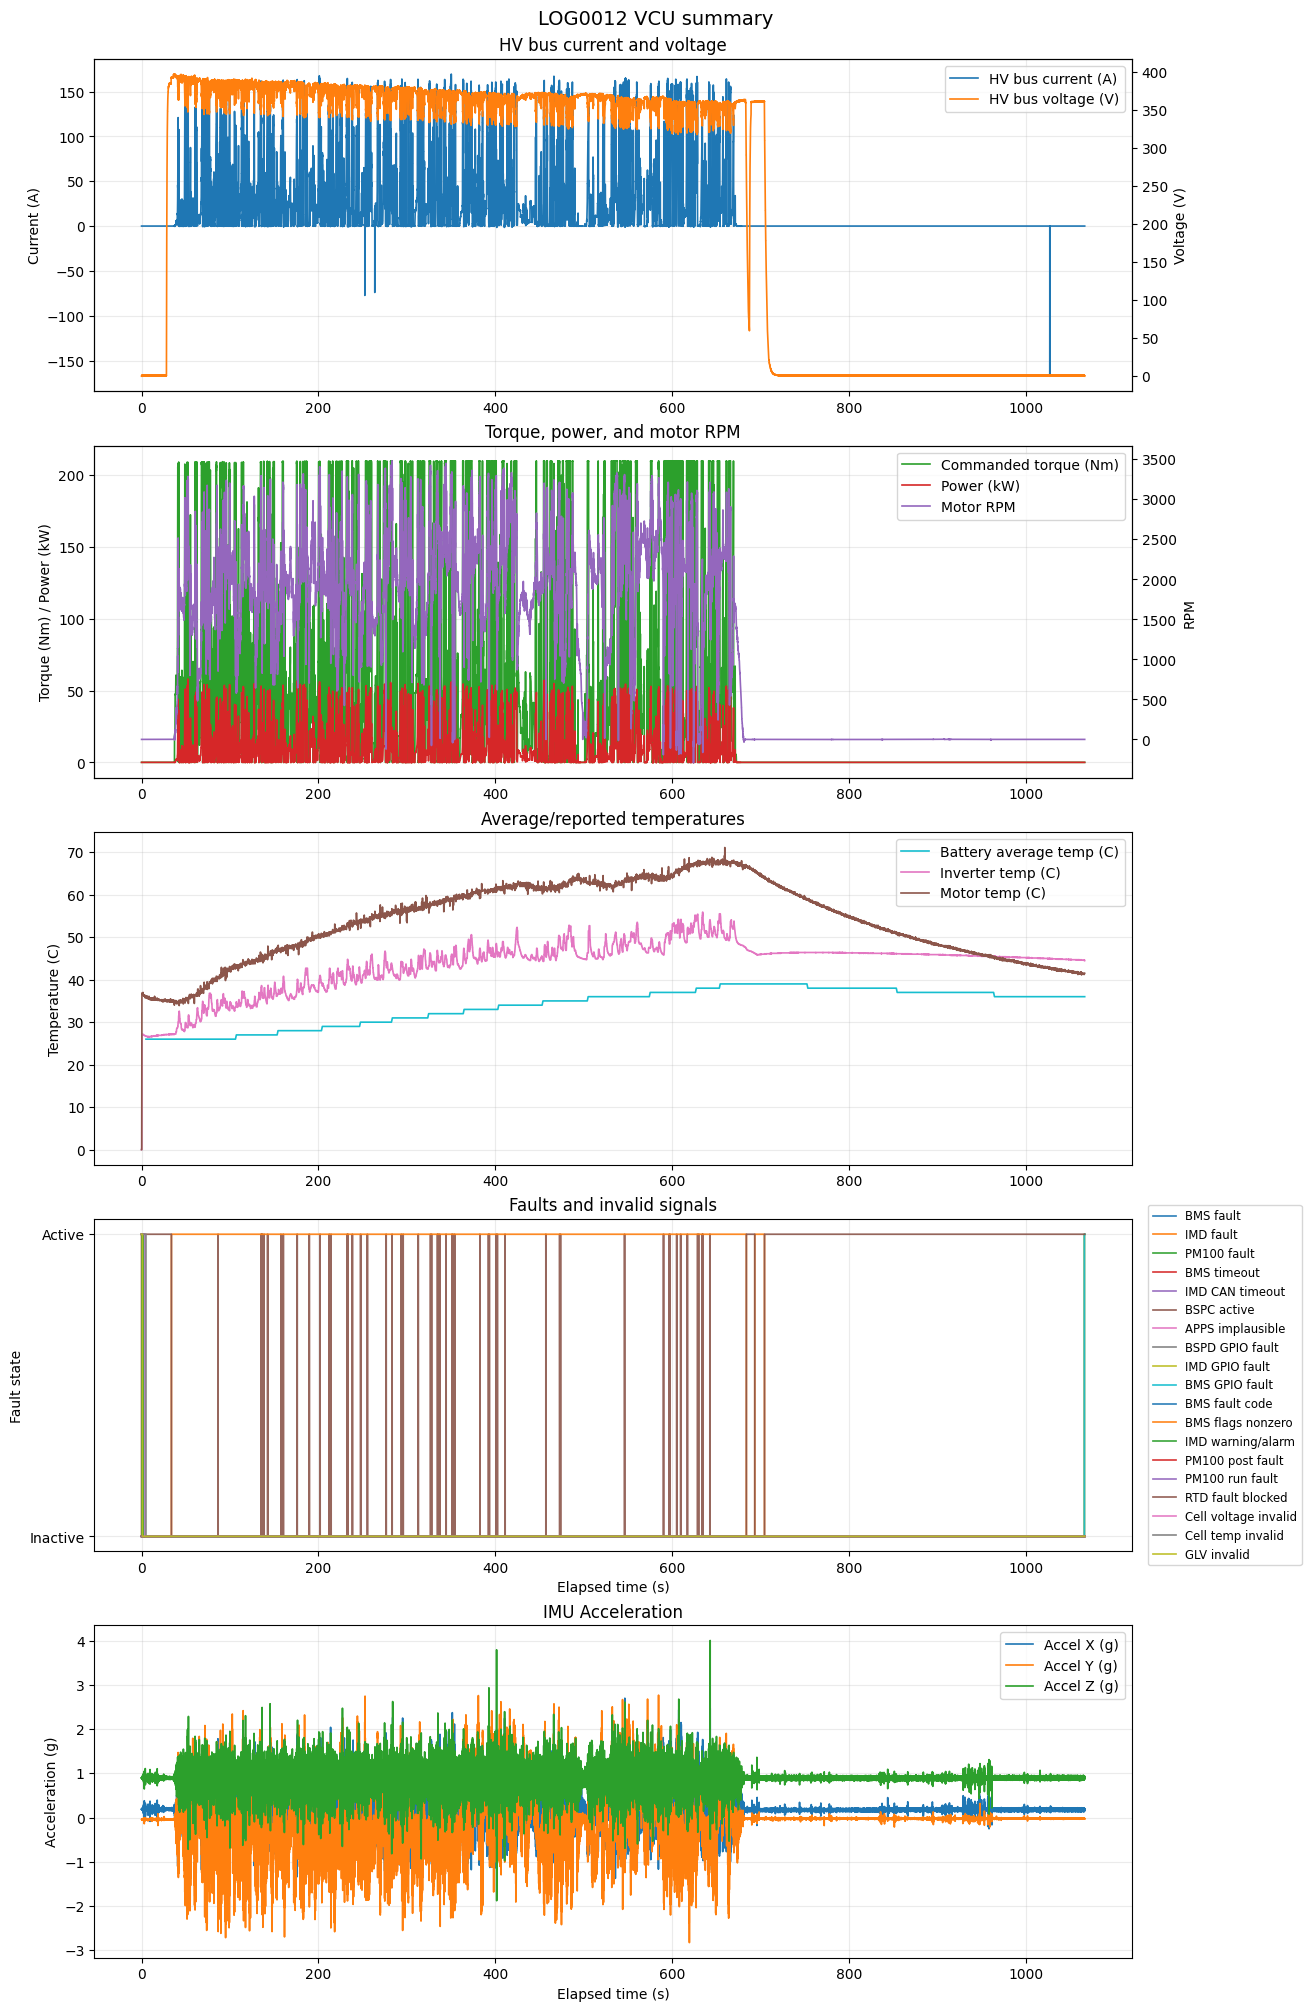

In [6]:
metrics_by_log = summarize_vcu_logs(
    logs,
    log_numbers=LOG_NUMBERS,
    max_points=MAX_POINTS_PER_TRACE,
)
